# Storyboard sequence generation


In [132]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [133]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

PROJECT_DIR = Path('/content/drive/MyDrive/project')
PANEL_DIR = PROJECT_DIR / 'panels'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'controlnet_batch_csa_off'

seq_name = 'seq02'
out_dir = OUTPUT_DIR / seq_name

print(f"Panel directory: {PANEL_DIR}")
print(f"Reading saved sequence from: {out_dir}")

Panel directory: /content/drive/MyDrive/project/panels
Reading saved sequence from: /content/drive/MyDrive/project/outputs/controlnet_batch_csa_off/seq02


In [134]:
import os

# 1. Resolve and check the panels folder
panels_dir = Path(PANEL_DIR)
if not panels_dir.is_dir():
    raise FileNotFoundError(f"Panels folder not found: {panels_dir}")

# 2. Collect and sort image files (e.g., png, jpg, jpeg)
valid_extensions = {'.png', '.jpg', '.jpeg', '.webp'}
img_files = sorted([f for f in panels_dir.iterdir() if f.suffix.lower() in valid_extensions])
print(f"Found {len(img_files)} panel images in {panels_dir}")

# 3. Load original images
originals = []
for f in img_files:
    try:
        img = Image.open(f).convert('RGB')
        originals.append(img)
    except Exception as e:
        print(f"Warning: Failed to load {f.name} - {e}")
        originals.append(None)

# 4. Correct panel_paths to match the actual list of paths for the plotting code
panel_paths = [str(f) for f in img_files]

# 5. Initialize placeholders for frames and statuses (to match the originals for display purposes)
# Replace these placeholders with your actual frame sequences and generation status lists later
frames = [Image.new('RGB', (100, 100), color='gray') for _ in originals]
statuses = ['Placeholder' for _ in originals]


Found 16 panel images in /content/drive/MyDrive/project/panels


In [135]:
# Load actual generated frames and metadata from out_dir
from pathlib import Path
import json

print(f"Scanning directory: {out_dir}")

# Match only the generated panel images (e.g., panel01.png, panel02.png, ...)
frame_files = sorted([
    f for f in Path(out_dir).iterdir()
    if f.name.startswith("panel") and f.suffix.lower() in {'.png', '.jpg', '.jpeg', '.webp'}
    and "_cond" not in f.name
])

real_frames = []
real_statuses = []

for i, panel_path in enumerate(panel_paths):
    if i < len(frame_files):
        try:
            img_path = frame_files[i]
            img = Image.open(img_path).convert('RGB')
            real_frames.append(img)
            real_statuses.append("Generated")
            print(f"Loaded frame {i+1}: {img_path.name}")
        except Exception as e:
            real_frames.append(Image.new('RGB', (100, 100), color='red'))
            real_statuses.append("Error loading")
    else:
        real_frames.append(Image.new('RGB', (100, 100), color='gray'))
        real_statuses.append("Missing")

# Update active variables used by the display cell
frames = real_frames
statuses = real_statuses

Scanning directory: /content/drive/MyDrive/project/outputs/controlnet_batch_csa_off/seq02
Loaded frame 1: panel01.png
Loaded frame 2: panel02.png
Loaded frame 3: panel03.png
Loaded frame 4: panel04.png
Loaded frame 5: panel05.png
Loaded frame 6: panel06.png


In [136]:
import os
import glob

# --- Define a sequence: same character described the same way in every prompt ---
panel_files = sorted(glob.glob(os.path.join(PANEL_DIR, f'{seq_name}_panel*.png')))
CHAR_A_DESC = "blonde boy wearing a blue shirt and white rounded hood"
CHAR_B_DESC = "simple yellow round bulldog with big eyes"
SETTING = "bedroom"

# 6 panels
actions = [
    f"{CHAR_A_DESC} sitting in a bed and talking with pointing a finger",
    f"{CHAR_B_DESC} sitting on the floor looking up",
    f"{CHAR_B_DESC} leans back on a pillow on the floor",
    f"{CHAR_A_DESC} looking scared with wide eyes while {CHAR_B_DESC} is leaning back",
    f"{CHAR_B_DESC} still leaning back and picks up a part of a donut",
    f"{CHAR_B_DESC} holding a part of a donut near their mouth"
][:len(panel_files)]

prompts_2 = [f"{a}, {SETTING}" for a in actions]

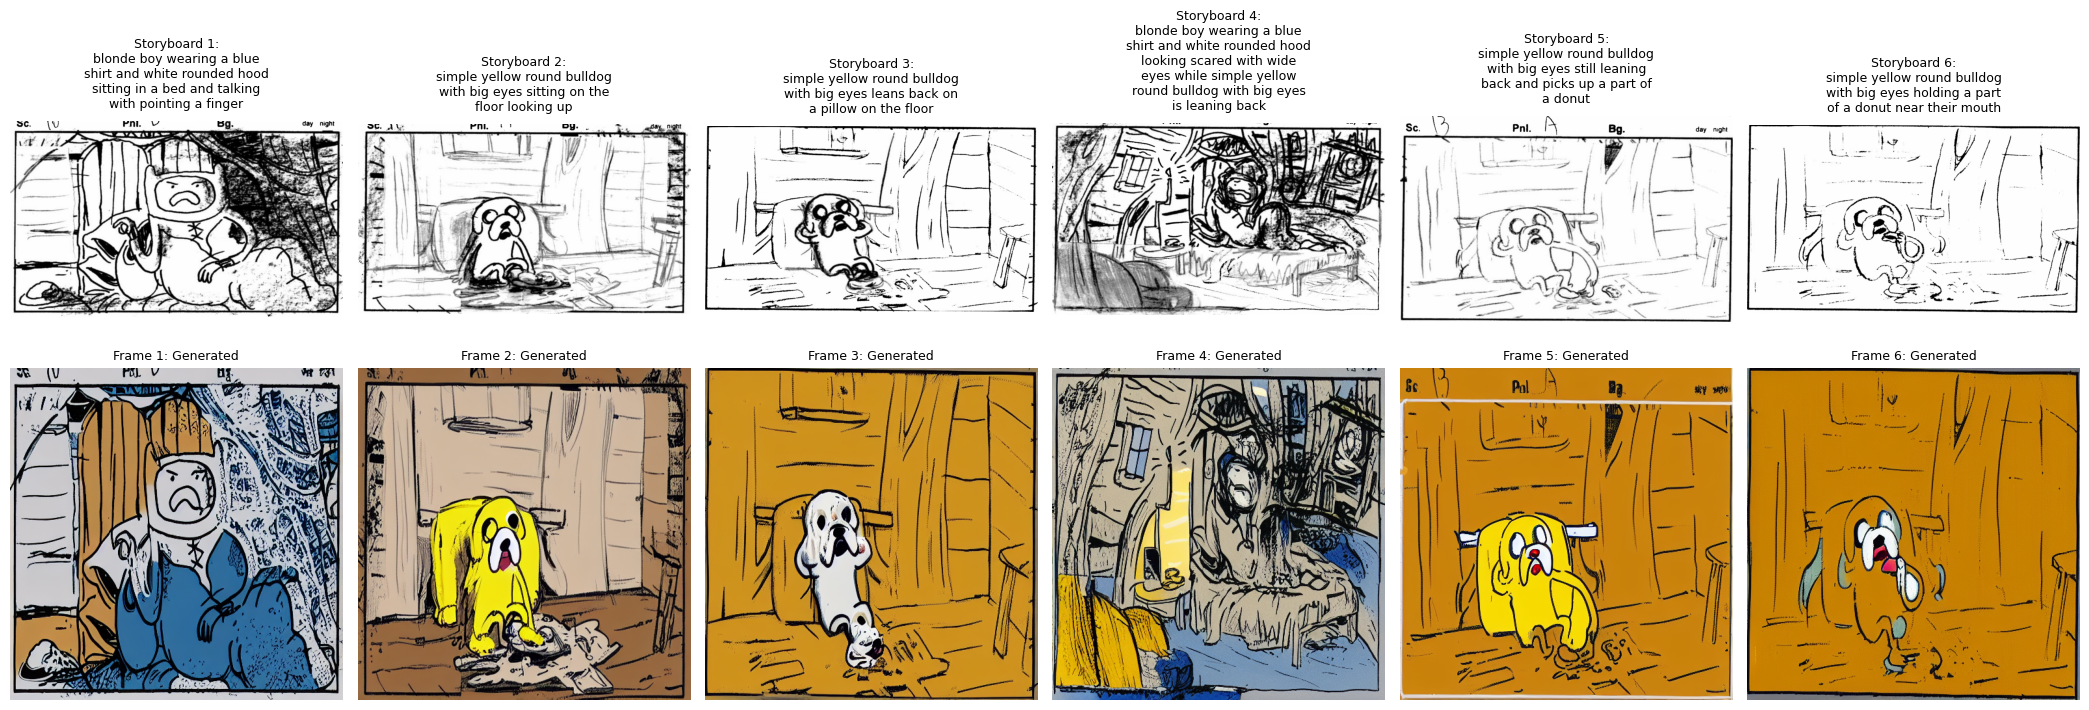

In [137]:
import textwrap

# Filter to only keep the 6 panels corresponding to seq02
num_seq02_panels = 6
seq02_originals = originals[6:12] if len(originals) >= 12 else originals[:num_seq02_panels]
seq02_frames = frames[:num_seq02_panels]
seq02_statuses = statuses[:num_seq02_panels]

fig, axes = plt.subplots(2, num_seq02_panels, figsize=(3.5 * num_seq02_panels, 7.5))

if num_seq02_panels == 1:
    axes = axes.reshape(2, 1)

for column, (original, frame, status) in enumerate(zip(seq02_originals, seq02_frames, seq02_statuses)):
    # Get matching action/prompt description if available
    action_desc = ""
    if column < len(actions):
        action_desc = actions[column]

    wrapped_title = "\n".join(textwrap.wrap(action_desc, width=28))

    if original is not None:
        axes[0, column].imshow(original)
    else:
        axes[0, column].text(0.5, 0.5, 'Panel unreadable', ha='center', va='center')

    axes[0, column].set_title(f'Storyboard {column + 1}:\n{wrapped_title}', fontsize=9, pad=10)
    axes[1, column].imshow(frame)
    axes[1, column].set_title(f'Frame {column + 1}: {status}', fontsize=9)

    axes[0, column].axis('off')
    axes[1, column].axis('off')

plt.tight_layout()
plt.show()

In [138]:
import json
import os

# Correct path is directly in the local Colab directory
notebook_path = '/content/drive/MyDrive/project/character_crop.ipynb'

with open(notebook_path, 'r', encoding='utf-8') as f:
    nb_data = json.load(f)

# Print the code cells to understand what needs to be integrated
for i, cell in enumerate(nb_data.get('cells', [])):
    if cell.get('cell_type') == 'code':
        print(f"--- Code Cell {i+1} ---")
        print("".join(cell.get('source', [])))
        print("\n")

--- Code Cell 1 ---
from pathlib import Path
from typing import Protocol, TypeAlias

from PIL import Image

import torch

from transformers import (
    AutoProcessor,
    Florence2ForConditionalGeneration,
)

from transformers import Sam2Model, Sam2Processor


BBox: TypeAlias = tuple[int, int, int, int]


--- Code Cell 2 ---
class CharacterLocator(Protocol):
    """Locates a requested character within an image."""

    def locate(
        self,
        image: Image.Image,
        prompt: str,
    ) -> BBox:
        """
        Locate a character and return its bounding box.

        Args:
            image: Source image.
            prompt: Character description such as "the vampire".

        Returns:
            Bounding box as (left, top, right, bottom).
        """
        ...


--- Code Cell 3 ---
class CharacterSegmenter(Protocol):
    """Segments a character using a supplied bounding box."""

    def segment(
        self,
        image: Image.Image,
        bbox: BBox,
    ) -

In [139]:
# Read all code from character_crop.ipynb and compile them sequentially
import json

with open(notebook_path, 'r', encoding='utf-8') as f:
    nb_data = json.load(f)

# Combine all code cells from 1 to 8 (definition cells)
combined_code_lines = []
for i, cell in enumerate(nb_data.get('cells', [])):
    # Skip initialization / demo cells (cells 9, 10, 11, 12, 13)
    if cell.get('cell_type') == 'code' and i < 8:
        combined_code_lines.extend(cell.get('source', []))
        combined_code_lines.append('\n\n')

combined_code = "".join(combined_code_lines)

# We will write this content directly to a new file, then load or print it,
# but since we want to run and make it available in the notebook:
exec(combined_code)
print("Successfully imported and executed all classes/functions from character_crop.ipynb:")
print("- CharacterLocator, Florence2CharacterLocator")
print("- CharacterSegmenter, SAM2CharacterSegmenter")
print("- BackgroundStrategy, TransparentBackgroundStrategy, SolidBackgroundStrategy")
print("- CharacterReferenceExtractor")

Successfully imported and executed all classes/functions from character_crop.ipynb:
- CharacterLocator, Florence2CharacterLocator
- CharacterSegmenter, SAM2CharacterSegmenter
- BackgroundStrategy, TransparentBackgroundStrategy, SolidBackgroundStrategy
- CharacterReferenceExtractor


In [140]:
import logging
from typing import Union, List, Dict, Optional, Tuple, Any

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
import numpy as np

# Configure Logger
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("IdentityStabilityEvaluator")

class IdentityStabilityEvaluator:
    """
    Computes Inter-Frame Identity Stability across a sequence of generated character frames
    using deep features extracted from Meta's DINOv2 models.

    Isolates character identity by cropping to bounding boxes from provided binary masks,
    masks out non-character pixels to prevent background leakage, and extracts normalized embeddings.
    """
    def __init__(
        self,
        model_size: str = "vitb14",
        device: Optional[str] = None,
        drift_threshold: float = 0.70,
        padding_color: int = 0  # 0 for Black padding
    ) -> None:
        """
        Initializes the evaluation pipeline by loading the DINOv2 feature extractor.

        Args:
            model_size: Scale of the DINOv2 model to pull ('vitb14' or 'vitl14').
            device: Execution device. Defaults to auto-select (CUDA if available).
            drift_threshold: Cut-off cosine similarity threshold to trigger drift alerts.
            padding_color: RGB value (0-255) for background padding pixels.
        """
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.drift_threshold = drift_threshold
        self.padding_color = padding_color

        repo = "facebookresearch/dinov2"
        model_name = f"dinov2_{model_size}"
        logger.info(f"Loading DINOv2 model ({model_name}) from torch.hub on {self.device}...")
        self.model = torch.hub.load(repo, model_name).to(self.device)
        self.model.eval()

        # Standard ImageNet pre-processing required by DINOv2
        self.transform = T.Compose([
            T.Resize((224, 224)),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def _to_pil(self, img: Union[str, Path, Image.Image, torch.Tensor]) -> Image.Image:
        """Helper to load or convert any image inputs into standard PIL RGB Format."""
        if isinstance(img, (str, Path)):
            return Image.open(img).convert("RGB")
        elif isinstance(img, torch.Tensor):
            # Expected [C, H, W]
            img_np = img.mul(255).byte().cpu().numpy().transpose(1, 2, 0)
            return Image.fromarray(img_np).convert("RGB")
        elif isinstance(img, Image.Image):
            return img.convert("RGB")
        else:
            raise TypeError(f"Unsupported image input type: {type(img)}")

    def _preprocess_character_region(
        self,
        frame: Image.Image,
        mask: Optional[Image.Image]
    ) -> Tuple[Optional[torch.Tensor], bool]:
        """
        Extracts the character from the frame by cropping it to the mask's
        bounding box and masking out the non-character background.

        Returns:
            Processed image tensor or None if the frame/mask is blank/invalid.
            Boolean indicating if the frame failed validation.
        """
        # Check for blank / empty physical inputs
        img_np = np.array(frame)
        if img_np.mean() < 5:
            return None, True

        if mask is None:
            # If no mask, fallback to entire frame
            masked_img = frame
        else:
            mask_gray = mask.convert("L")
            mask_np = np.array(mask_gray)

            if mask_np.sum() == 0:
                return None, True

            # Apply mask to keep character and fill back with self.padding_color
            background = Image.new("RGB", frame.size, color=(self.padding_color, self.padding_color, self.padding_color))
            masked_img = Image.composite(frame, background, mask_gray)

            # Obtain bounding box coordinates of character to crop tightly
            bbox = mask_gray.getbbox()
            if bbox:
                masked_img = masked_img.crop(bbox)

        # Prepare for Vision Transformer
        tensor_img = self.transform(masked_img).unsqueeze(0).to(self.device)
        return tensor_img, False

    @torch.no_grad()
    def get_embedding(self, tensor_img: torch.Tensor) -> torch.Tensor:
        """Extracts and L2-normalizes the DINOv2 CLS feature embedding vector."""
        features = self.model(tensor_img)
        normalized_features = F.normalize(features, p=2, dim=1)
        return normalized_features.squeeze(0)

    def evaluate_sequence(
        self,
        frames: List[Union[str, Path, Image.Image, torch.Tensor]],
        masks: List[Optional[Image.Image]],
        reference_image: Optional[Union[str, Path, Image.Image, torch.Tensor]] = None
    ) -> Dict[str, Any]:
        """
        Evaluates inter-frame stability of identity sequences.
        """
        num_frames = len(frames)
        embeddings: Dict[int, torch.Tensor] = {}
        failed_indices: List[int] = []

        # 1. Process active frames & compile valid character embeddings
        for idx in range(num_frames):
            try:
                pil_frame = self._to_pil(frames[idx])
                pil_mask = masks[idx] if idx < len(masks) else None

                char_tensor, is_failed = self._preprocess_character_region(pil_frame, pil_mask)
                if is_failed or char_tensor is None:
                    logger.warning(f"Frame {idx} marked as blank or character missing! Skipping.")
                    failed_indices.append(idx)
                    continue

                embeddings[idx] = self.get_embedding(char_tensor)
            except Exception as e:
                logger.error(f"Error processing frame index {idx}: {e}")
                failed_indices.append(idx)

        # 2. Reference Image embedding extraction
        ref_embedding: Optional[torch.Tensor] = None
        if reference_image is not None:
            try:
                ref_pil = self._to_pil(reference_image)
                ref_tensor, ref_failed = self._preprocess_character_region(ref_pil, None)
                if not ref_failed and ref_tensor is not None:
                    ref_embedding = self.get_embedding(ref_tensor)
            except Exception as e:
                logger.error(f"Failed to process Reference Image: {e}")

        # 3. Compute Metrics
        consecutive_scores: List[float] = []
        drift_detected = False

        # Sort active frames indices
        active_indices = sorted(list(embeddings.keys()))

        # Compute consecutive frame transition metrics
        for i in range(len(active_indices) - 1):
            idx1, idx2 = active_indices[i], active_indices[i+1]
            sim = torch.dot(embeddings[idx1], embeddings[idx2]).item()
            consecutive_scores.append(float(sim))
            if sim < self.drift_threshold:
                drift_detected = True

        mean_consecutive = float(np.mean(consecutive_scores)) if consecutive_scores else 0.0

        # Compute full sequence pairwise correlation matrices and off-diagonal summaries
        all_pairs_sim: List[float] = []
        for idx_i in active_indices:
            for idx_j in active_indices:
                if idx_i < idx_j:
                    sim = torch.dot(embeddings[idx_i], embeddings[idx_j]).item()
                    all_pairs_sim.append(float(sim))

        global_pairwise = float(np.mean(all_pairs_sim)) if all_pairs_sim else 0.0

        # Compute reference fidelity scores
        reference_scores: Optional[List[float]] = None
        if ref_embedding is not None:
            reference_scores = []
            for idx in range(num_frames):
                if idx in embeddings:
                    sim = torch.dot(embeddings[idx], ref_embedding).item()
                    reference_scores.append(float(sim))
                else:
                    reference_scores.append(0.0) # Masked/failed marker placeholder value

        return {
            "consecutive_scores": consecutive_scores,
            "mean_consecutive_similarity": mean_consecutive,
            "global_pairwise_similarity": global_pairwise,
            "reference_fidelity_scores": reference_scores,
            "drift_detected": drift_detected,
            "failed_frames": failed_indices
        }

if __name__ == "__main__":
    # Executable sample module walkthrough verification
    print("--- Executing IdentityStabilityEvaluator Verification Block ---")
    evaluator = IdentityStabilityEvaluator(model_size="vitb14")

    # Generate simulated images to demonstrate pipeline robustness
    mock_image_1 = Image.new("RGB", (300, 300), color=(180, 50, 50))  # red character blob
    mock_mask_1 = Image.new("L", (300, 300), color=0)
    ImageDraw = Image.new("L", (300, 300))
    # Create character masked active area inside mask
    mock_mask_1.paste(255, [50, 50, 250, 250])

    mock_image_2 = Image.new("RGB", (300, 300), color=(170, 50, 50))  # adjacent consistent panel
    mock_mask_2 = mock_mask_1.copy()

    mock_image_3 = Image.new("RGB", (300, 300), color=(0, 0, 0))      # simulated blank/black frame failure
    mock_mask_3 = Image.new("L", (300, 300), color=0)

    mock_reference = Image.new("RGB", (300, 300), color=(190, 45, 45))

    frames_sequence = [mock_image_1, mock_image_2, mock_image_3]
    masks_sequence = [mock_mask_1, mock_mask_2, mock_mask_3]

    # Compute and display analytical summary output dict
    summary = evaluator.evaluate_sequence(
        frames=frames_sequence,
        masks=masks_sequence,
        reference_image=mock_reference
    )

    print("\nSummary Metric Dictionary:")
    for k, v in summary.items():
        print(f"{k}: {v}")


--- Executing IdentityStabilityEvaluator Verification Block ---


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main



Summary Metric Dictionary:
consecutive_scores: [0.9992502927780151]
mean_consecutive_similarity: 0.9992502927780151
global_pairwise_similarity: 0.9992502927780151
reference_fidelity_scores: [0.9975199699401855, 0.9941680431365967, 0.0]
drift_detected: False
failed_frames: [2]


Initializing Florence-2 and SAM 2 for character extraction...


Loading weights:   0%|          | 0/665 [00:00<?, ?it/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Processing generated sequence frames...


<string>:366: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)


Frame 1: Character extracted successfully.
Frame 2: Character extracted successfully.
Frame 3: Character extracted successfully.
Frame 4: Character extracted successfully.
Frame 5: Character extracted successfully.
Frame 6: Character extracted successfully.


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main



=== IDENTITY STABILITY METRICS ===
Global Sequence Stability Index (Mean Pairwise Similarity): 0.4675
Mean Consecutive Similarity: 0.4395
Drift Detected: True

Consecutive Scene-to-Scene Similarity Scores:
  Frame 1 -> Frame 2: 0.2927
  Frame 2 -> Frame 3: 0.6470
  Frame 3 -> Frame 4: 0.1822
  Frame 4 -> Frame 5: 0.3681
  Frame 5 -> Frame 6: 0.7075


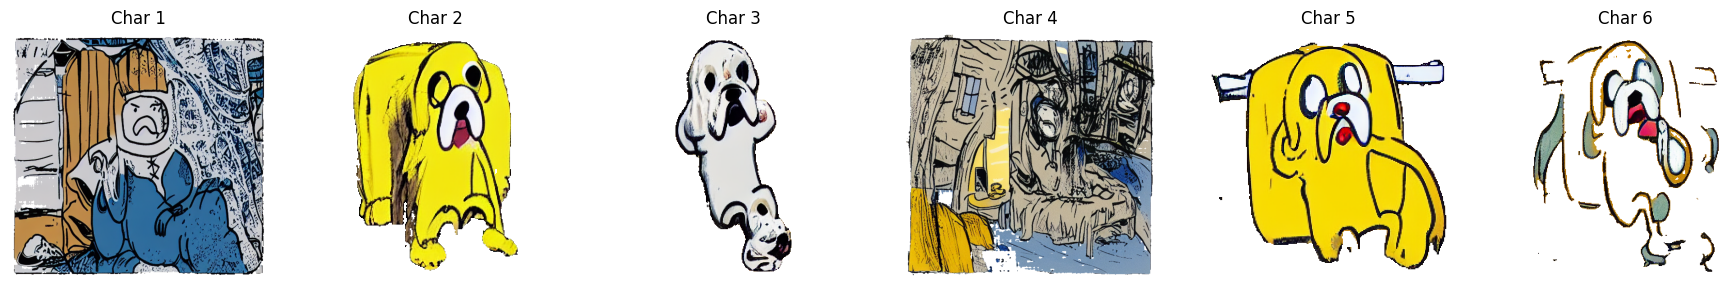

In [141]:
# Filter to only keep the 6 panels corresponding to seq02
seq02_frames = frames[:6]

# 1. Initialize character extraction components
print("Initializing Florence-2 and SAM 2 for character extraction...")
locator = Florence2CharacterLocator()
segmenter = SAM2CharacterSegmenter()
extractor = CharacterReferenceExtractor(
    locator=locator,
    segmenter=segmenter,
    background_strategy=TransparentBackgroundStrategy(),
    padding=10,
)

# 2. Extract masks and cropped character images from our generated frames
character_images = []
character_masks = []

print("Processing generated sequence frames...")
for idx, frame_img in enumerate(seq02_frames):
    try:
        # Locate and segment "the vampire"
        bbox = locator.locate(frame_img, "the vampire")
        mask = segmenter.segment(frame_img, bbox)

        # Save crop & mask
        character_masks.append(mask)

        # Extract isolated character image
        cropped_char = extractor.extract(frame_img, "the vampire")
        character_images.append(cropped_char)
        print(f"Frame {idx+1}: Character extracted successfully.")
    except Exception as e:
        print(f"Frame {idx+1}: Extraction failed or character not found. {e}")
        character_masks.append(None)
        character_images.append(None)

# 3. Evaluate identity stability across the sequence
evaluator = IdentityStabilityEvaluator(model_size="vitb14")
evaluation_results = evaluator.evaluate_sequence(
    frames=seq02_frames,
    masks=character_masks
)

# 4. Show the extracted character sequence and print calculated scores
print("\n=== IDENTITY STABILITY METRICS ===")
print(f"Global Sequence Stability Index (Mean Pairwise Similarity): {evaluation_results['global_pairwise_similarity']:.4f}")
print(f"Mean Consecutive Similarity: {evaluation_results['mean_consecutive_similarity']:.4f}")
print(f"Drift Detected: {evaluation_results['drift_detected']}")
if evaluation_results['failed_frames']:
    print(f"Failed/Skipped Frames: {evaluation_results['failed_frames']}")

print("\nConsecutive Scene-to-Scene Similarity Scores:")
for i, score in enumerate(evaluation_results['consecutive_scores']):
    print(f"  Frame {i+1} -> Frame {i+2}: {score:.4f}")

# Plot the segmented character crops (specifically for seq02_frames)
fig, axes = plt.subplots(1, len(seq02_frames), figsize=(3 * len(seq02_frames), 3))
if len(seq02_frames) == 1:
    axes = [axes]

for i, char_img in enumerate(character_images):
    if char_img is not None:
        axes[i].imshow(char_img)
        axes[i].set_title(f"Char {i+1}")
    else:
        axes[i].text(0.5, 0.5, "N/A", ha='center', va='center')
        axes[i].set_title(f"Frame {i+1} (Failed)")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

               IDENTITY STABILITY RESULTS                 
Total Sequence Stability Score (Global Mean): 0.4675
Mean Consecutive Step Similarity:            0.4395
-----------------------------------------------------------
Consecutive Scene-to-Scene Similarity Scores:
  Scene 1 -> Scene 2: 0.2927
  Scene 2 -> Scene 3: 0.6470
  Scene 3 -> Scene 4: 0.1822
  Scene 4 -> Scene 5: 0.3681
  Scene 5 -> Scene 6: 0.7075



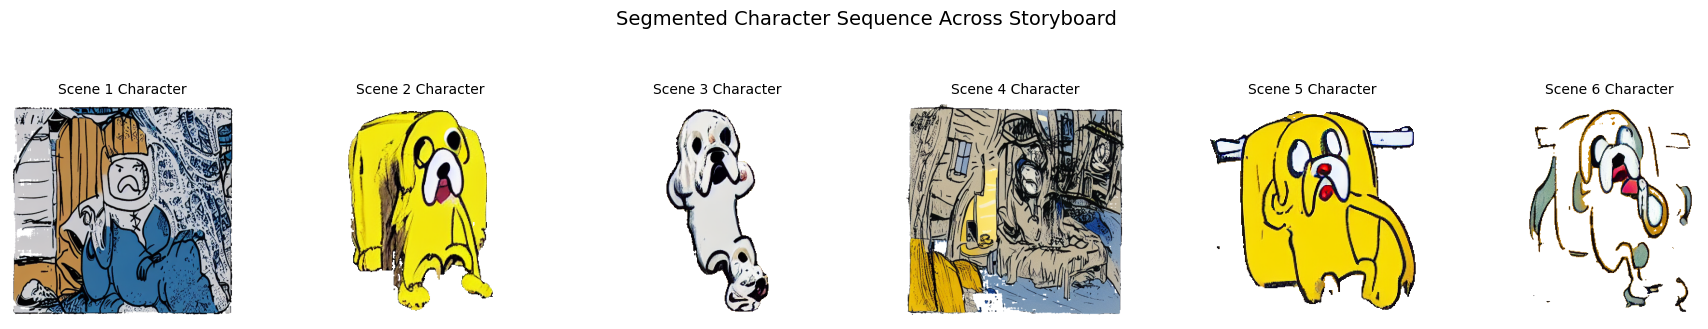

In [142]:
seq02_character_images = character_images[:6]
consecutive_scores = evaluation_results.get('consecutive_scores', [])[:5]
global_score = evaluation_results.get('global_pairwise_similarity', 0.0)
mean_consecutive = evaluation_results.get('mean_consecutive_similarity', 0.0)

print("===========================================================")
print("               IDENTITY STABILITY RESULTS                 ")
print("===========================================================")
print(f"Total Sequence Stability Score (Global Mean): {global_score:.4f}")
print(f"Mean Consecutive Step Similarity:            {mean_consecutive:.4f}")
print("-----------------------------------------------------------")
print("Consecutive Scene-to-Scene Similarity Scores:")
for idx, score in enumerate(consecutive_scores):
    print(f"  Scene {idx+1} -> Scene {idx+2}: {score:.4f}")
print("===========================================================\n")

# Display the 6 isolated character sequence panels
fig, axes = plt.subplots(1, len(seq02_character_images), figsize=(3 * len(seq02_character_images), 3))
if len(seq02_character_images) == 1:
    axes = [axes]

for i, char_img in enumerate(seq02_character_images):
    if char_img is not None:
        axes[i].imshow(char_img)
        axes[i].set_title(f"Scene {i+1} Character", fontsize=10)
    else:
        axes[i].text(0.5, 0.5, 'N/A\n(Missing/Failed)', ha='center', va='center', color='red')
        axes[i].set_title(f"Scene {i+1}", fontsize=10)
    axes[i].axis('off')

plt.suptitle("Segmented Character Sequence Across Storyboard", fontsize=14, y=1.08)
plt.tight_layout()
plt.show()